## Activity 1 — Bag-of-Words (CountVectorizer)
**Objective:** Read movie reviews, convert them to a Bag-of-Words representation, inspect vocabulary size, and display the first five rows and ten columns of the document-term matrix.

**Concepts:** Token, vocabulary, corpus, document-term matrix, sparse matrix, word counts.

In [5]:
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import CountVectorizer

from pathlib import Path
import pandas as pd

csv_path = Path(r"C:\Users\warya\Desktop\BDS-6A\NLP\LABS\movie_reviews.csv")

print("File exists:", csv_path.exists())

df = pd.read_csv(csv_path)


required = {'text', 'label'}
if not required.issubset(df.columns):
    raise ValueError('Dataset must contain columns: text and label')
df = df.dropna(subset=['text', 'label']).copy()
df['text'] = df['text'].astype(str)
df['label'] = df['label'].astype(str).str.strip().str.lower()
if set(df['label'].unique()) != {'positive', 'negative'}:
    raise ValueError("This lab expects both labels 'positive' and 'negative'.")
if df['label'].value_counts().min() < 2:
    raise ValueError('At least two reviews per class are needed for training and testing.')

vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(df['text'])
print('Number of reviews:', len(df))
print('Class distribution:\n', df['label'].value_counts().to_string())
print('Vocabulary size:', len(vectorizer.vocabulary_))
print('Document-term matrix shape:', X_bow.shape)
print('First 5 documents x first 10 features:')
print(pd.DataFrame(X_bow[:5, :10].toarray(),
                   columns=vectorizer.get_feature_names_out()[:10]).to_string(index=False))

File exists: True
Number of reviews: 40
Class distribution:
 label
positive    20
negative    20
Vocabulary size: 111
Document-term matrix shape: (40, 111)
First 5 documents x first 10 features:
 acting  again  amazing  and  annoying  awful  bad  beautiful  boring  brilliant
      1      0        0    1         0      0    0          0       0          0
      0      0        0    1         0      0    0          1       0          1
      0      0        1    1         0      0    0          0       0          0
      0      0        0    1         0      0    0          0       0          0
      1      0        0    1         0      0    0          0       0          0


### Activity 1 — Interpretation
The **corpus** is the collection of reviews; each review is a **document**. `CountVectorizer` builds a **vocabulary** of distinct tokens and converts each review into a fixed-length row of **word counts**. The matrix has one row per review and one column per vocabulary term. Most entries are zero because each review uses only a few words, so scikit-learn stores it as a **sparse matrix**. Bag-of-Words ignores word order and cannot directly understand meaning or negation. The exact vocabulary size depends on the loaded dataset.

## Activity 2 — TF-IDF Representation
**Objective:** Transform the same reviews using TF-IDF and compare the raw counts and TF-IDF weights of two frequent words (`the`, `was`) in a review containing them.

**Concepts:** Term Frequency (TF), Document Frequency (DF), Inverse Document Frequency (IDF), TF-IDF weighting.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df['text'])
print('TF-IDF matrix shape:', X_tfidf.shape)

# Find a review containing both target words, where possible.
target_words = ['the', 'was']
shared = set(vectorizer.vocabulary_) & set(tfidf_vectorizer.vocabulary_)
if not all(w in shared for w in target_words):
    target_words = sorted(shared, key=lambda w: -int((X_bow[:, vectorizer.vocabulary_[w]] > 0).sum()))[:2]
if len(target_words) < 2:
    raise ValueError('Dataset needs at least two shared vocabulary words.')
matching = [i for i, review in enumerate(df['text'])
            if all(X_bow[i, vectorizer.vocabulary_[w]] > 0 for w in target_words)]
doc_idx = matching[0] if matching else 0
print('Selected review:', df.iloc[doc_idx]['text'])
for word in target_words:
    bow_idx = vectorizer.vocabulary_[word]
    tfidf_idx = tfidf_vectorizer.vocabulary_[word]
    count = int(X_bow[doc_idx, bow_idx])
    weight = float(X_tfidf[doc_idx, tfidf_idx])
    doc_frequency = int((X_bow[:, bow_idx] > 0).sum())
    print(f"Word '{word}': raw count={count}, TF-IDF weight={weight:.4f}, document frequency={doc_frequency}/{len(df)}")
print('Note: raw counts and normalized TF-IDF weights have different scales;')
print('a common term receives less IDF emphasis than a rare term, but its numeric TF-IDF')
print('value is not guaranteed to be lower than its raw count in every comparison.')

TF-IDF matrix shape: (40, 111)
Selected review: The movie was wonderful and the acting was excellent
Word 'the': raw count=2, TF-IDF weight=0.3937, document frequency=24/40
Word 'was': raw count=2, TF-IDF weight=0.3833, document frequency=25/40
Note: raw counts and normalized TF-IDF weights have different scales;
a common term receives less IDF emphasis than a rare term, but its numeric TF-IDF
value is not guaranteed to be lower than its raw count in every comparison.


### Activity 2 — Interpretation
**TF-IDF** gives a term more importance when it is frequent in a particular document but less importance when it appears in many documents. Thus, common words such as *the* and *was* tend to have less discriminating power than distinctive sentiment words. Scikit-learn uses **smoothed IDF and L2 normalization by default**, so its exact weights differ from the simplified formula in the handout. Compare terms' relative importance rather than assuming a TF-IDF number must always be smaller than its raw count. Each word's column index is looked up in its **own** vectorizer.

## Activity 3 — Train Multinomial Naive Bayes and Logistic Regression
**Objective:** Split data into training and testing portions (80%/20%), fit TF-IDF only on training reviews, train both models, and generate test predictions.

**Concepts:** Supervised learning, features and labels, training/test split, generative versus discriminative classifiers, data leakage.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Split raw reviews BEFORE learning TF-IDF weights to prevent test-set leakage.
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42,
    stratify=df['label']
)
train_vectorizer = TfidfVectorizer()
X_train = train_vectorizer.fit_transform(X_train_text)
X_test = train_vectorizer.transform(X_test_text)

nb_model = MultinomialNB()
lr_model = LogisticRegression(max_iter=1000, random_state=42)
nb_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)
lr_preds = lr_model.predict(X_test)

print('Training reviews:', len(X_train_text), '| Test reviews:', len(X_test_text))
print('Training features:', X_train.shape[1])
print(pd.DataFrame({'Actual': y_test.to_numpy(),
                    'Naive Bayes': nb_preds,
                    'Logistic Regression': lr_preds}).to_string(index=False))

Training reviews: 32 | Test reviews: 8
Training features: 96
  Actual Naive Bayes Logistic Regression
negative    positive            positive
negative    positive            positive
positive    positive            positive
positive    negative            negative
negative    positive            positive
positive    positive            positive
negative    negative            negative
positive    positive            positive


### Activity 3 — Interpretation
Both classifiers learn from **labeled examples** of positive and negative reviews. **Multinomial Naive Bayes** estimates class-specific word evidence using Bayes' theorem and a conditional-independence assumption. **Logistic Regression** learns feature weights that distinguish classes and maps its score to a probability. A fixed random seed makes the split reproducible; **stratification** preserves class proportions. Fitting TF-IDF only on the training set avoids **data leakage** from test reviews. Predictions alone do not establish which classifier is better; Activity 4 measures that.

## Activity 4 — Evaluate Both Models
**Objective:** Calculate accuracy, precision, recall and F1-score for each classifier and display each confusion matrix.

**Concepts:** TP, TN, FP, FN, positive class, precision–recall trade-off, confusion matrix.


--- Multinomial Naive Bayes ---
Accuracy: 0.5000
Precision: 0.5000
Recall: 0.7500
F1: 0.6000
Confusion matrix (rows=actual, columns=predicted; negative, positive):
[[1 3]
 [1 3]]


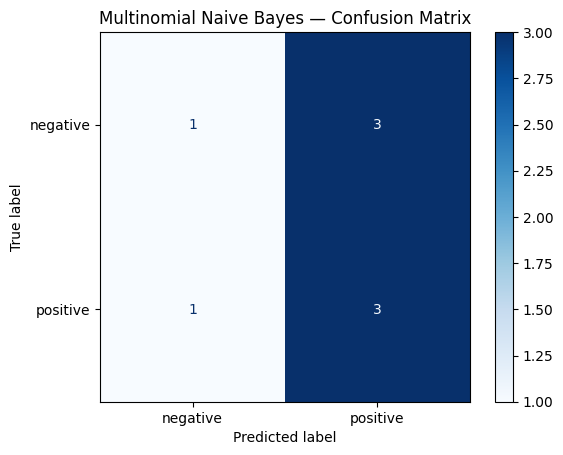


--- Logistic Regression ---
Accuracy: 0.5000
Precision: 0.5000
Recall: 0.7500
F1: 0.6000
Confusion matrix (rows=actual, columns=predicted; negative, positive):
[[1 3]
 [1 3]]


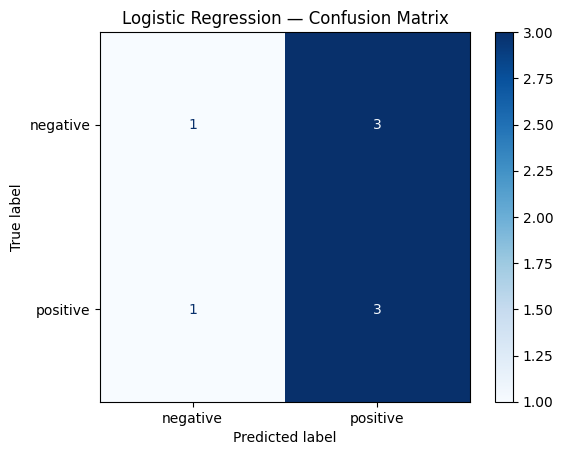


Side-by-side evaluation:
                     Accuracy  Precision  Recall   F1
Naive Bayes               0.5        0.5    0.75  0.6
Logistic Regression       0.5        0.5    0.75  0.6
Selected model (F1 first, accuracy as tiebreaker): Naive Bayes


In [4]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

def evaluate_and_print(model_name, y_true, y_pred):
    scores = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='positive', zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label='positive', zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label='positive', zero_division=0)
    }
    cm = confusion_matrix(y_true, y_pred, labels=['negative', 'positive'])
    print(f'\n--- {model_name} ---')
    for metric, value in scores.items():
        print(f'{metric}: {value:.4f}')
    print('Confusion matrix (rows=actual, columns=predicted; negative, positive):')
    print(cm)
    ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(cmap='Blues', values_format='d')
    plt.title(f'{model_name} — Confusion Matrix')
    plt.show()
    return scores

nb_scores = evaluate_and_print('Multinomial Naive Bayes', y_test, nb_preds)
lr_scores = evaluate_and_print('Logistic Regression', y_test, lr_preds)
comparison = pd.DataFrame([nb_scores, lr_scores],
                          index=['Naive Bayes', 'Logistic Regression'])
print('\nSide-by-side evaluation:')
print(comparison.round(4).to_string())
# F1 is the selection criterion; ties are resolved using accuracy, then Naive Bayes.
best_model_name = max(comparison.index,
                      key=lambda name: (comparison.loc[name, 'F1'], comparison.loc[name, 'Accuracy']))
print('Selected model (F1 first, accuracy as tiebreaker):', best_model_name)

### Activity 4 — Interpretation
**Accuracy** is the fraction of all predictions that are correct. **Precision** asks: of the reviews predicted positive, how many were truly positive? **Recall** asks: of the truly positive reviews, how many were detected? **F1-score** balances precision and recall. In the confusion matrix, rows are **actual** labels and columns are **predicted** labels, ordered negative then positive. The notebook chooses the better model primarily by positive-class **F1**, with accuracy as a tiebreaker. Results from the small illustrative dataset can vary and are not reliable estimates of real-world performance.

## Activity 5 — Build an End-to-End NLP Pipeline
**Objective:** Combine TF-IDF with the selected classifier and predict sentiment for three unseen movie-review sentences.

**Concepts:** Pipeline, preprocessing consistency, inference, unseen data, model deployment.

In [5]:
from sklearn.pipeline import Pipeline

chosen_classifier = (MultinomialNB() if best_model_name == 'Naive Bayes'
                     else LogisticRegression(max_iter=1000, random_state=42))
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', chosen_classifier)
])
pipeline.fit(X_train_text, y_train)

# Optional: replace these examples by putting one review per line in new_reviews.txt.
review_file = Path('new_reviews.txt')
if review_file.exists():
    new_reviews = [line.strip() for line in review_file.read_text(encoding='utf-8').splitlines()
                   if line.strip()]
    if not new_reviews:
        print('new_reviews.txt is empty; using three built-in unseen examples.')
        new_reviews = [
            'The movie was excellent with wonderful acting and a beautiful story.',
            'This film was boring with terrible acting and a weak plot.',
            'The movie had interesting moments but the ending was disappointing.'
        ]
else:
    print('new_reviews.txt not found; using three built-in unseen examples.')
    new_reviews = [
        'The movie was excellent with wonderful acting and a beautiful story.',
        'This film was boring with terrible acting and a weak plot.',
        'The movie had interesting moments but the ending was disappointing.'
    ]
new_preds = pipeline.predict(new_reviews)
for i, (review, prediction) in enumerate(zip(new_reviews, new_preds), start=1):
    print(f'{i}. Review: {review}\n   Predicted sentiment: {prediction}\n')
print('Pipeline steps:', list(pipeline.named_steps))

new_reviews.txt not found; using three built-in unseen examples.
1. Review: The movie was excellent with wonderful acting and a beautiful story.
   Predicted sentiment: positive

2. Review: This film was boring with terrible acting and a weak plot.
   Predicted sentiment: negative

3. Review: The movie had interesting moments but the ending was disappointing.
   Predicted sentiment: negative

Pipeline steps: ['tfidf', 'classifier']


### Activity 5 — Interpretation
A **Pipeline** combines the trained text vectorizer and classifier into one object. During training, `.fit()` learns the TF-IDF vocabulary and classifier parameters from training reviews. During **inference**, `.predict()` applies the *same fitted transformation* to new text before classification. This avoids mismatched feature columns and simplifies deployment. The three predictions are **model outputs, not verified ground truth**; mixed reviews can be difficult for simple Bag-of-Words/TF-IDF models because word order and context are limited.